In [163]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [164]:
import pandas as pd
import numpy as np
import json
import random
import ipywidgets as widgets
from src.utils import df_features_to_numpy, df_target_to_numpy, run_experiment_pytorch_clasificacion, run_experiment_pytorch_regresion, permutation_importance_pytorch
from sklearn.preprocessing import StandardScaler
from src.splitting import split_estratificado_autor
from sklearn.neighbors import NearestNeighbors
from IPython.display import display

# Cargo los datasets

In [165]:
#LEO TEST
chunks_test = pd.read_json("set_test_1.json", lines=True, chunksize=100_000)
chunk_list_test = []
for chunk in chunks_test:
    chunk_list_test.append(chunk)
df_test = pd.concat(chunk_list_test, ignore_index=True)

#LEO VAL
chunks_val = pd.read_json("set_val_1.json", lines=True, chunksize=100_000)
chunk_list_val = []
for chunk in chunks_val:
    chunk_list_val.append(chunk)
df_val = pd.concat(chunk_list_val, ignore_index=True)

#LEO TRAIN
chunks_train = pd.read_json("set_train_1.json", lines=True, chunksize=100_000)
chunk_list_train = []
for chunk in chunks_train:
    chunk_list_train.append(chunk)
df_train = pd.concat(chunk_list_train, ignore_index=True)

#LEO AUTORES
chunks_autores = pd.read_json("goodreads_book_authors.json", lines=True, chunksize=100_000)
chunk_list_autores = []
for chunk in chunks_autores:
    chunk_list_autores.append(chunk)
df_autores = pd.concat(chunk_list_autores, ignore_index=True)

# Preparacion de los datos

Utilizo el dataset de autores para asociar los IDs que ya tenemos, con sus nombres correspondientes:

In [166]:
descripcion_emb_train = np.load("descripcion_emb_train.npy")
descripcion_emb_val = np.load("descripcion_emb_val.npy")
descripcion_emb_test = np.load("descripcion_emb_test.npy")

In [167]:
#Creo las columnas para el dataset:
descripcion_colum = [f"description_emb_{num}" for num in range(50)]

descripcion_emb_train_df = pd.DataFrame(descripcion_emb_train, columns = descripcion_colum, index = df_train.index)
df_train = df_train.join(descripcion_emb_train_df)

descripcion_emb_val_df = pd.DataFrame(descripcion_emb_val, columns = descripcion_colum, index = df_val.index)
df_val = df_val.join(descripcion_emb_val_df)

descripcion_emb_test_df = pd.DataFrame(descripcion_emb_test, columns = descripcion_colum, index = df_test.index)
df_test = df_test.join(descripcion_emb_test_df)

In [168]:
#UNIFICO TRAIN, VAL, TEST EN UN UNICO DF 
df = pd.concat([df_train, df_val, df_test], ignore_index=True)

In [169]:
#Al hacer merge, usamos "how = left" para que quedarnos con todas las muestras de df_train (aunque no lo encuentre coincidencia).
#Si no encuentra el ID de df en df_autores, simplemente completa con NaN
df = df.merge(df_autores[["author_id", "name"]], left_on = "author_id_principal", right_on = "author_id", how = "left")
#Despues del merge, tenemos entonces entre las columnas a : "author_id_principal", "author_id" y "author_name"
#Pero como son el mismo ID, elimino una de las dos:
df = df.drop(columns = "author_id")
#Renombro la columna:
df = df.rename(columns = {"name": "author_name"})
df["titulo_autor"] = (df["title"] + " — " + df["author_name"]) #Para la interfaz

Es mas facil eliminar las features con las que no queremos entrenar, que quedarnos con las que si, son muchas mas. 

In [170]:
df_recomendador = df[["titulo_autor", "title", "author_name", "author_id_principal"]]
df = df.drop(columns = ["author_id_principal", "title_key", "publisher", "title_text", "author_name", "titulo_autor", "language_code", "ratings_count", "authors", "format_group", "genres", "description", "title"])

In [171]:
print(df.columns.tolist())

['publication_year', 'num_pages', 'average_rating', 'is_series', 'AUDIO', 'COMIC', 'EBOOK', 'HARDCOVER', 'OTHER', 'PAPERBACK', 'UNKNOWN', 'adventure', 'biography', 'children', 'classics', 'contemporary', 'crime', 'dystopian', 'fantasy', 'fiction', 'graphic novel', 'historical', 'history', 'horror', 'humor', 'memoir', 'mystery', 'non fiction', 'paranormal', 'poetry', 'psychology', 'religion', 'romance', 'science fiction', 'self help', 'short stories', 'thriller', 'urban', 'young adult', 'language_code_ang', 'language_code_en', 'language_code_en-CA', 'language_code_en-GB', 'language_code_en-US', 'language_code_eng', 'language_code_enm', 'language_code_gem', 'language_code_sco', 'cantidad_generos', 'estrellas', 'description_emb_0', 'description_emb_1', 'description_emb_2', 'description_emb_3', 'description_emb_4', 'description_emb_5', 'description_emb_6', 'description_emb_7', 'description_emb_8', 'description_emb_9', 'description_emb_10', 'description_emb_11', 'description_emb_12', 'descr

Dejo esto por si queremos testear solo con las features basicas

In [172]:
#generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
#features = ["is_series", "publication_year", "num_pages", 'AUDIO', 'COMIC', 'EBOOK', 'HARDCOVER', 'OTHER', 'PAPERBACK', "language_code_ang", "language_code_en", "language_code_en-CA", "language_code_en-GB", "language_code_en-US", "language_code_eng", "language_code_enm", "language_code_gem", "language_code_sco", "cantidad_generos"] + generos #'format_group_UNKNOWN' la saco por el one hot en regresion
#
##Me quedo solo con las features necesarias para el modelo base y las estandarizo
#dfs = [df_train, df_val, df_test]
#y_train_regresion, y_val_regresion, y_test_regresion = df_target_to_numpy("average_rating", dfs)
#y_train_clasificacion, y_val_clasificacion, y_test_clasificacion = df_target_to_numpy("estrellas", dfs)
#X_train, X_val, X_test = df_features_to_numpy(features, dfs)
#
##estandarizo los datos
#scaler = StandardScaler()
#X_train_scaled = scaler.fit_transform(X_train)
#X_val_scaled = scaler.transform(X_val) #escala X_val con los valores sacados de X_train
##TODO: escalar el X_test

In [173]:
X = df.to_numpy()

#estandarizo los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Implementacion de los modeloKNNKNNs

## 1. KNN - K nearest neighboors

In [174]:
modeloKNN = NearestNeighbors(n_neighbors = 20, metric = "cosine")
modeloKNN.fit(X_scaled)

,n_neighbors,20
,radius,1.0
,algorithm,'auto'
,leaf_size,30
,metric,'cosine'
,p,2
,metric_params,None
,n_jobs,None


## 2. KMeans
En primer lugar elijo el mejor k

In [175]:
#from sklearn.metrics import silhouette_score
#from sklearn.cluster import KMeans
#from src.graficos import plot_silhouette_inercia
#
#silhouettes = []
#inertias = []
#ks = [k for k in range(3, 21)]
#
##como calcular silhouette es muy pesado, predigo sobre un sample aleatorio con menos muestras
#np.random.seed(42)
#idx = np.random.choice(len(X_scaled), size=10000, replace=False)
#X_sample = X_scaled[idx]
#
#for k in ks:
#    print(f"k = {k}")
#    kmeans = KMeans(n_clusters = k, random_state = 42, n_init = 10) #n_init: cant de veces q se vuelve a correr el algoritmo con diferentes centroides, ayuda a obtener mejores resultados, deja de depender tanto del centroide inicial elegido
#    kmeans.fit(X_scaled)
#
#    #para inertia
#    inertias.append(kmeans.inertia_)
#
#    #para silhouette
#    clusters = kmeans.predict(X_sample)
#    silhouettes.append(silhouette_score(X_sample, clusters))
#
#plot_silhouette_inercia(ks, silhouettes, inertias)

In [176]:
#import numpy as np
#import matplotlib.pyplot as plt
#from sklearn.cluster import KMeans
#from sklearn.manifold import TSNE
#
## Elegir el número de clusters
#k = 10
#
## Entrenar K-Means
#kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
#clusters = kmeans.fit_predict(X_scaled)
#
## Tomar una muestra aleatoria para visualizar
#np.random.seed(42)
#n_samples = 5000
#idx = np.random.choice(len(X_scaled), size=n_samples, replace=False)
#
#X_sample = X_scaled[idx]
#clusters_sample = clusters[idx]
#
## Aplicar t-SNE
#tsne = TSNE(
#    n_components=2,
#    perplexity=30,
#    random_state=42,
#    init="pca"
#)
#
#X_tsne = tsne.fit_transform(X_sample)
#
## Graficar
#plt.figure(figsize=(10, 8))
#scatter = plt.scatter(
#    X_tsne[:, 0],
#    X_tsne[:, 1],
#    c=clusters_sample,
#    cmap="tab20",
#    s=8,
#    alpha=0.7
#)
#
#plt.colorbar(scatter, label="Cluster")
#plt.title(f"t-SNE visualization of K-Means clusters (k={k})")
#plt.xlabel("t-SNE 1")
#plt.ylabel("t-SNE 2")
#plt.tight_layout()
#plt.show()

In [177]:
#k = 10
#kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
#clusters = kmeans.fit_predict(X)
#df["cluster"] = clusters #guardo en el df el cluster al que pertenece cada libro
#
##testers, desp ver si sacar
#print(df["cluster"].value_counts().sort_index()) #cant de libros en cada cluster
#for clus in range(1, 10):
#    print(df[df["cluster"] == clus][["title", "author_name"]].head(20)) #libros en un cierto cluster


# Desarrollando recomendador

Una vez ya entrenado el modelo, vuelvo a unificar df_recomendador (con las features no numericas necesarias para identificar al libro) y df (con las features necesarias para entrenar)

In [178]:
df = pd.concat([df_recomendador, df], axis=1)

In [179]:
def recomendar(modeloKNN, X, indice_libro, n_recomendaciones = 10):
    distancias, indices = modeloKNN.kneighbors(X[indice_libro].reshape(1, -1), n_neighbors = n_recomendaciones + 1)
    return indices[0][1:], distancias[0][1:]

Ejemplo de recomendador para un libro especifico:

In [180]:
idx = df[df_recomendador["title"] == "The Book Thief"].index[0]
recomendados, distancias = recomendar(modeloKNN, X_scaled, idx, 10)

print("\nRecomendaciones:")
for idx, dist in zip(recomendados, distancias):
    print(f"{df_recomendador.iloc[idx]['title']}  (distancia = {dist:.4f})")


Recomendaciones:
The Book of Aron  (distancia = 0.1875)
Alone In Berlin  (distancia = 0.2720)
The Color Purple  (distancia = 0.2776)
The Reader  (distancia = 0.2892)
Revolution  (distancia = 0.3011)
Your Heart is a Muscle the Size of a Fist  (distancia = 0.3032)
The Orphan's Tale  (distancia = 0.3117)
The Idiot  (distancia = 0.3138)
Salvage the Bones  (distancia = 0.3174)
The Secret Life of Bees  (distancia = 0.3187)


### Trato de implementar lo de Titulo + autor

In [181]:
#Para evitar tener que recorrer el dataset de libros cada vez que quiero buscar un libro, 
#me creo un diccionario que asocia "titulo_autor" con su indice:
titulo_a_indice = dict(zip(df["titulo_autor"], df.index)) #Reduce el tiempo de busqueda, lo que nos sirve con el dataset grande

In [182]:
def recomendar_por_libro(modelo, libros_df, X, titulo_autor, titulo_a_indice = titulo_a_indice, cant_recomendaciones = 5):
    #Observaciones: la interfaz ya obliga al usuario a elegir un unico libro (al especificar tambien el autor),
    #entonces ya no hace chequear el caso en el que len(resultados) > 1

    #Ahora hay que ver que hacemos con cada posible situacion:
    #Primer caso: No encontramos ningun libro con esos datos
    if (titulo_autor not in titulo_a_indice):
        print("No se encontro ningun libro con esos datos.")
        return None
    
    #Segundo caso: se encontro el libro
    indice_libro = titulo_a_indice[titulo_autor]
    #Obtengo las recomendaciones:
    libros_recomendados, distancias = recomendar(modelo, X, indice_libro, cant_recomendaciones)
    recomendaciones = libros_df.iloc[libros_recomendados].copy()
    recomendaciones["distancia"] = distancias
    columnas = ["title", "author_name", "publication_year"]
    return recomendaciones[columnas]

In [183]:
all_titles = sorted(df["titulo_autor"].dropna().unique().tolist())

book_selector = widgets.Combobox(
    placeholder="Escribí un libro...",
    options=[],
    description="Libro:",
    ensure_option=False
)

def actualizar_opciones(change):
    texto = change["new"] or ""
    if len(texto) < 2:
        book_selector.options = []
        return
    matches = [t for t in all_titles if texto.lower() in t.lower()][:10]
    book_selector.options = matches

book_selector.observe(actualizar_opciones, names="value")

boton_recomendar = widgets.Button(
    description="Recomendar",
    button_style="success",
    icon="search"
)

salida = widgets.Output()

def al_hacer_click(boton):
    with salida:
        salida.clear_output()
        titulo_autor = book_selector.value
        recomendaciones = recomendar_por_libro(
            modeloKNN,
            df,
            X_scaled,
            titulo_autor,
            titulo_a_indice
        )
        if recomendaciones is not None:
            display(recomendaciones)

boton_recomendar.on_click(al_hacer_click)

display(book_selector)
display(boton_recomendar)
display(salida)

Combobox(value='', description='Libro:', placeholder='Escribí un libro...')

Button(button_style='success', description='Recomendar', icon='search', style=ButtonStyle())

Output()

In [184]:
all_titles = sorted(df["titulo_autor"].dropna().unique().tolist())

search_text = widgets.Text(
    placeholder="Escribí un libro...",
    description="Buscar:"
)

match_selector = widgets.Select(
    options=[],
    rows=10,
    layout=widgets.Layout(height="220px", width="600px")
)

boton_recomendar = widgets.Button(
    description="Recomendar",
    button_style="success",
    icon="search"
)

salida = widgets.Output()

def actualizar_opciones(change):
    texto = (change["new"] or "").strip().lower()
    if texto == "":
        match_selector.options = []
        return
    matches = [t for t in all_titles if texto in t.lower()][:50]
    match_selector.options = matches

def al_hacer_click(boton):
    with salida:
        salida.clear_output()
        titulo_autor = match_selector.value
        recomendaciones = recomendar_por_libro(
            modeloKNN,
            df,
            X_scaled,
            titulo_autor,
            titulo_a_indice
        )
        if recomendaciones is not None:
            display(recomendaciones)

search_text.observe(actualizar_opciones, names="value")
boton_recomendar.on_click(al_hacer_click)

display(search_text)
display(match_selector)
display(boton_recomendar)
display(salida)

Text(value='', description='Buscar:', placeholder='Escribí un libro...')

Select(layout=Layout(height='220px', width='600px'), options=(), rows=10, value=None)

Button(button_style='success', description='Recomendar', icon='search', style=ButtonStyle())

Output()

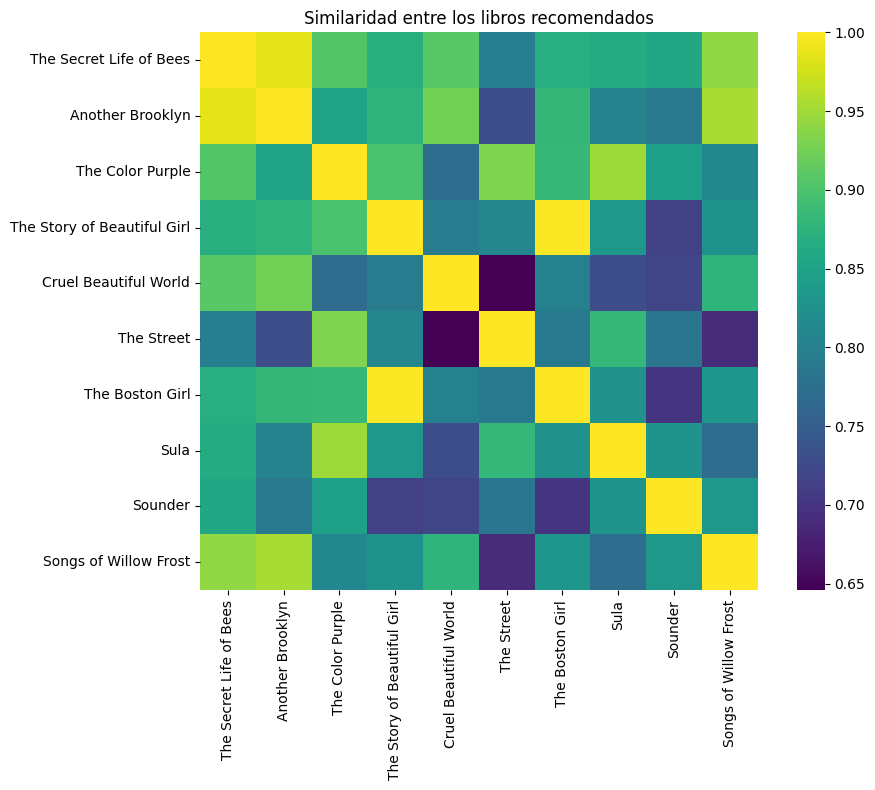

In [186]:
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt

# vecinos
distancias, indices = modeloKNN.kneighbors(
    X_scaled[idx].reshape(1,-1),
    n_neighbors=10
)

indices = indices[0]

X_vecinos = X_scaled[indices, :50]

sim = cosine_similarity(X_vecinos)

labels = df.iloc[indices]["title"].tolist()

plt.figure(figsize=(10,8))

sns.heatmap(
    sim,
    xticklabels=labels,
    yticklabels=labels,
    cmap="viridis",
    square=True
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.title("Similaridad entre los libros recomendados")
plt.tight_layout()
plt.show()

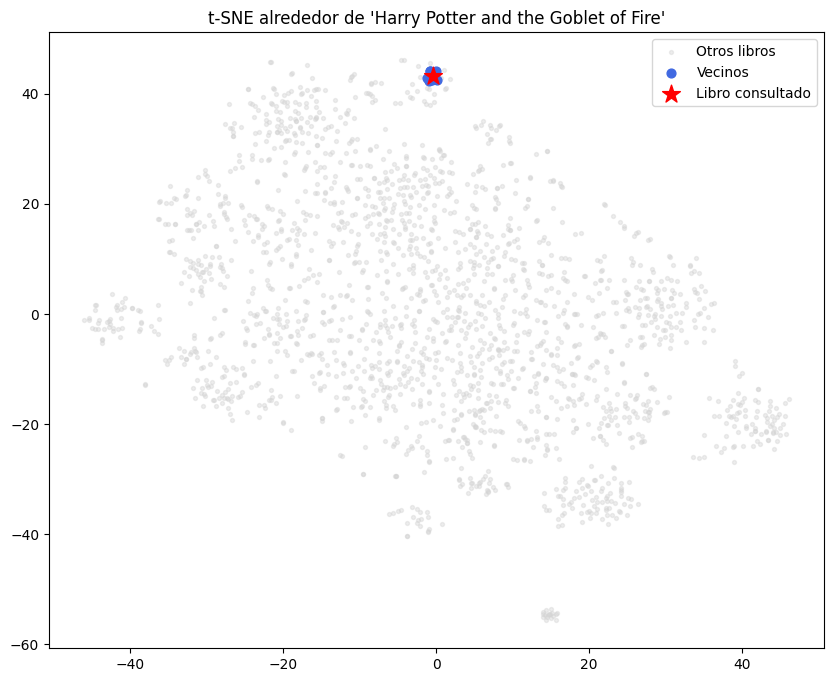

In [191]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# -------------------------
# Parámetros
# -------------------------
titulo = "Harry Potter and the Goblet of Fire"
n_random = 2000

#indice = titulo_a_indice[titulo]
indice = idx

# Vecinos (incluye el propio libro)
_, indices = modeloKNN.kneighbors(
    X_scaled[indice].reshape(1, -1),
    n_neighbors=11
)

indices = indices[0]

# -------------------------
# Muestra aleatoria
# -------------------------
np.random.seed(42)

muestra = np.random.choice(
    len(X_scaled),
    size=n_random,
    replace=False
)

# Agrego el libro y los vecinos
muestra = np.unique(np.concatenate([muestra, indices]))

X_plot = X_scaled[muestra]

# -------------------------
# t-SNE
# -------------------------
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    random_state=42
)

X_emb = tsne.fit_transform(X_plot)

# -------------------------
# Máscaras
# -------------------------
mask_libro = muestra == indice
mask_vecinos = np.isin(muestra, indices) & (~mask_libro)
mask_otros = ~(mask_libro | mask_vecinos)

# -------------------------
# Gráfico
# -------------------------
plt.figure(figsize=(10,8))

plt.scatter(
    X_emb[mask_otros,0],
    X_emb[mask_otros,1],
    s=8,
    color="lightgray",
    alpha=0.4,
    label="Otros libros"
)

plt.scatter(
    X_emb[mask_vecinos,0],
    X_emb[mask_vecinos,1],
    s=40,
    color="royalblue",
    label="Vecinos"
)

plt.scatter(
    X_emb[mask_libro,0],
    X_emb[mask_libro,1],
    s=180,
    color="red",
    marker="*",
    label="Libro consultado"
)

plt.title(f"t-SNE alrededor de '{titulo}'")
plt.legend()
plt.show()

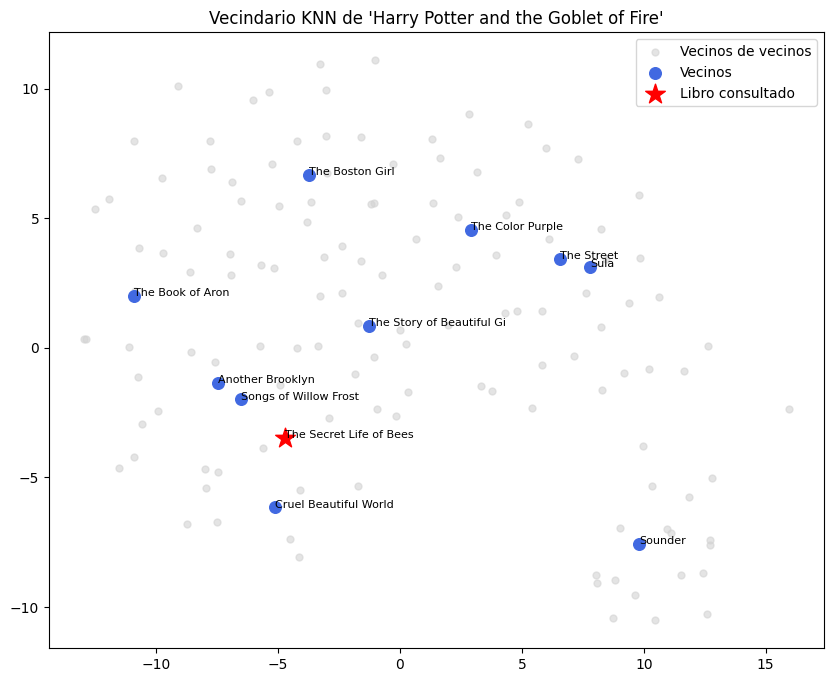

In [192]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# -------------------------
# Parámetros
# -------------------------
titulo = "Harry Potter and the Goblet of Fire"

#indice = titulo_a_indice[titulo]
indice = idx

# Primeros vecinos
_, vecinos = modeloKNN.kneighbors(
    X_scaled[indice].reshape(1,-1),
    n_neighbors=11
)

vecinos = vecinos[0]

# -------------------------
# Construyo un vecindario más grande
# -------------------------
indices = set(vecinos)

for i in vecinos:

    _, nuevos = modeloKNN.kneighbors(
        X_scaled[i].reshape(1,-1),
        n_neighbors=20
    )

    indices.update(nuevos[0])

indices = np.array(sorted(indices))

X_plot = X_scaled[indices]

# -------------------------
# t-SNE
# -------------------------
tsne = TSNE(
    n_components=2,
    perplexity=20,
    init="pca",
    random_state=42
)

X_emb = tsne.fit_transform(X_plot)

# -------------------------
# Máscaras
# -------------------------
mask_libro = indices == indice
mask_vecinos = np.isin(indices, vecinos) & (~mask_libro)
mask_otros = ~(mask_libro | mask_vecinos)

# -------------------------
# Gráfico
# -------------------------
plt.figure(figsize=(10,8))

plt.scatter(
    X_emb[mask_otros,0],
    X_emb[mask_otros,1],
    s=25,
    color="lightgray",
    alpha=0.6,
    label="Vecinos de vecinos"
)

plt.scatter(
    X_emb[mask_vecinos,0],
    X_emb[mask_vecinos,1],
    s=70,
    color="royalblue",
    label="Vecinos"
)

plt.scatter(
    X_emb[mask_libro,0],
    X_emb[mask_libro,1],
    s=220,
    color="red",
    marker="*",
    label="Libro consultado"
)

# Etiquetas de los vecinos
for i, idx in enumerate(indices):
    if idx == indice or idx in vecinos:
        plt.text(
            X_emb[i,0],
            X_emb[i,1],
            df.iloc[idx]["title"][:25],
            fontsize=8
        )

plt.title(f"Vecindario KNN de '{titulo}'")
plt.legend()
plt.show()